In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

nltk.download('stopwords')

print("Libraries imported successfully!")

Libraries imported successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [7]:
# Load Twitter dataset
df = pd.read_csv("twitter_training.csv")

# Display first five records
print(df.head())

# Display dataset information
print("\nDataset Information:")
print(df.info())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

   2401  Borderlands  Positive  \
0  2401  Borderlands  Positive   
1  2401  Borderlands  Positive   
2  2401  Borderlands  Positive   
3  2401  Borderlands  Positive   
4  2401  Borderlands  Positive   

  im getting on borderlands and i will murder you all ,  
0  I am coming to the borders and I will kill you...     
1  im getting on borderlands and i will kill you ...     
2  im coming on borderlands and i will murder you...     
3  im getting on borderlands 2 and i will murder ...     
4  im getting into borderlands and i can murder y...     

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74681 entries, 0 to 74680
Data columns (total 4 columns):
 #   Column                                                 Non-Null Count  Dtype 
---  ------                                                 --------------  ----- 
 0   2401                                                   74681 non-null  int64 
 1   Borderlands                                            74681 no

In [10]:
# Rename columns since the dataset has no header row
df.columns = ['id', 'entity', 'sentiment', 'text']

# Remove missing tweet records
df = df.dropna(subset=['text', 'sentiment'])

# Remove duplicate records
df = df.drop_duplicates()

# Clean tweet text
def clean_text(text):
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove mentions
    text = re.sub(r'@\w+', '', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Remove stopwords
    stop_words = set(stopwords.words('english'))
    words = text.split()
    words = [
        word for word in words
        if word not in stop_words
    ]

    return ' '.join(words)

# Apply cleaning
df['clean_text'] = df['text'].apply(clean_text)

print(df[['text', 'clean_text']].head())

                                                text  \
0  I am coming to the borders and I will kill you...   
1  im getting on borderlands and i will kill you ...   
2  im coming on borderlands and i will murder you...   
3  im getting on borderlands 2 and i will murder ...   
4  im getting into borderlands and i can murder y...   

                      clean_text  
0            coming borders kill  
1    im getting borderlands kill  
2   im coming borderlands murder  
3  im getting borderlands murder  
4  im getting borderlands murder  


sentiment
Negative      21698
Positive      19712
Neutral       17708
Irrelevant    12537
Name: count, dtype: int64


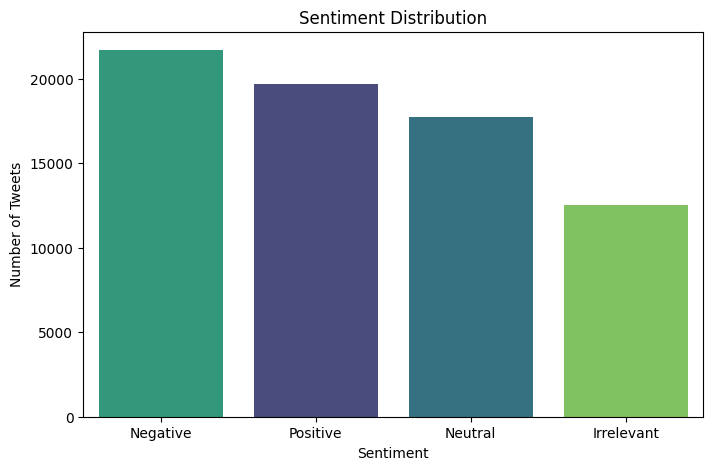

In [12]:
# Count positive, negative, neutral and irrelevant tweets
sentiment_counts = df['sentiment'].value_counts()
print(sentiment_counts)

# Plot sentiment distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='sentiment',
    hue='sentiment',
    order=df['sentiment'].value_counts().index,
    palette='viridis',
    legend=False
)

plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Tweets')
plt.show()

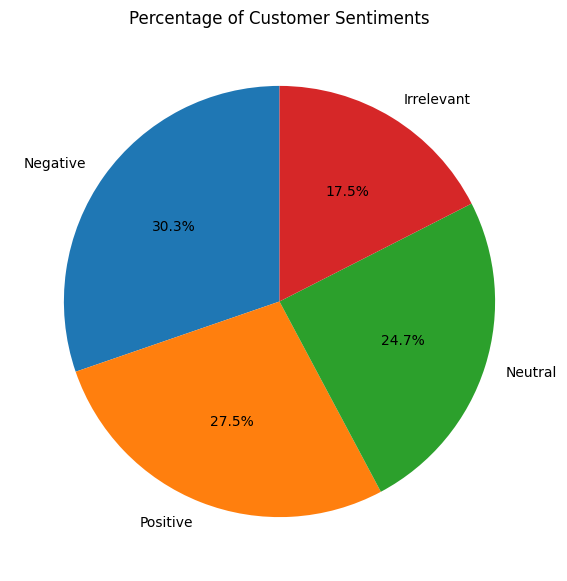

In [13]:
plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage of Customer Sentiments')
plt.show()

sentiment       Irrelevant  Negative  Neutral  Positive
entity                                                 
Amazon                 185       565     1197       302
ApexLegends            185       574      913       606
AssassinsCreed         256       365      153      1382
Battlefield            907       445      342       561
Borderlands            238       415      581       971


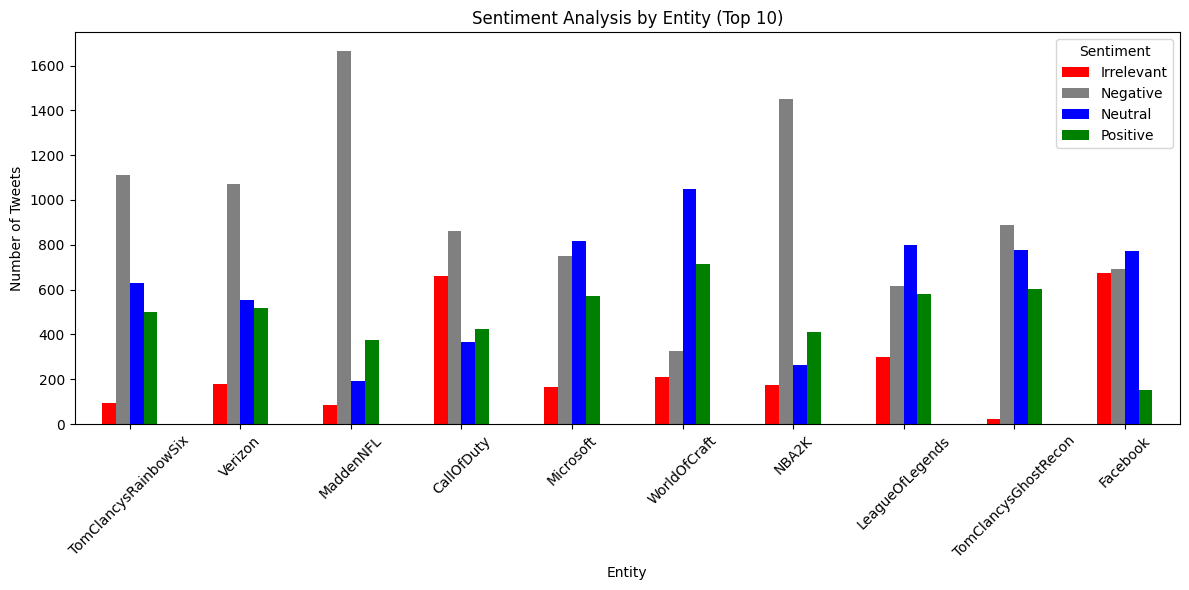

In [15]:
# Group sentiment by entity (company/game/airline)
entity_sentiment = pd.crosstab(
    df['entity'],
    df['sentiment']
)

# Display the first few rows of the crosstab
print(entity_sentiment.head())

# Visualize results for the top 10 most frequent entities for clarity
top_entities = df['entity'].value_counts().head(10).index
entity_sentiment_top = entity_sentiment.loc[top_entities]

entity_sentiment_top.plot(
    kind='bar',
    figsize=(12, 6),
    color=['red', 'gray', 'blue', 'green']
)

plt.title('Sentiment Analysis by Entity (Top 10)')
plt.xlabel('Entity')
plt.ylabel('Number of Tweets')
plt.xticks(rotation=45)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

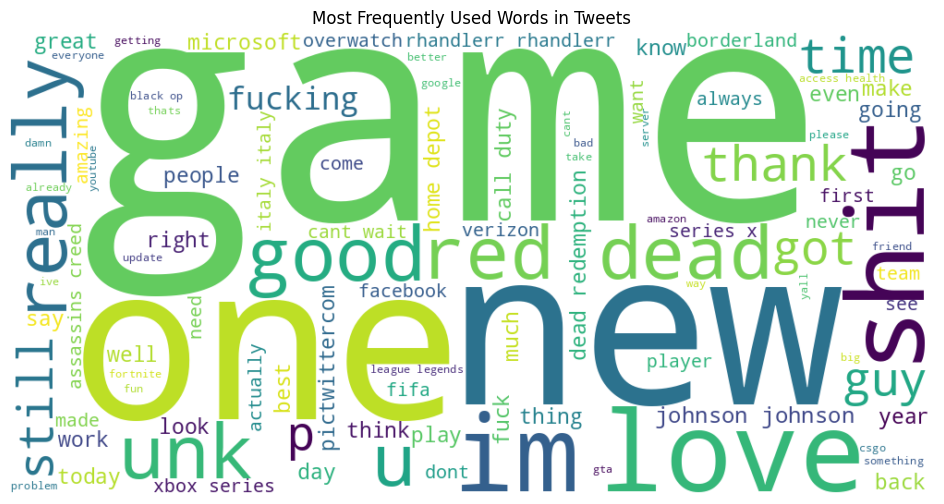

In [16]:
# Combine all cleaned tweets
all_words = ' '.join(df['clean_text'])

# Generate WordCloud
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    max_words=100
).generate(all_words)

plt.figure(figsize=(12, 6))

plt.imshow(wordcloud, interpolation='bilinear')

plt.axis('off')

plt.title('Most Frequently Used Words in Tweets')

plt.show()

In [18]:
# Define input and output
X = df['clean_text']
y = df['sentiment']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Convert text into numerical features
tfidf = TfidfVectorizer(
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Train model
model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

model.fit(X_train_tfidf, y_train)

print("Sentiment Model Trained Successfully!")

Sentiment Model Trained Successfully!


Model Accuracy: 67.06 %

Classification Report:
              precision    recall  f1-score   support

  Irrelevant       0.58      0.65      0.61      2507
    Negative       0.75      0.72      0.73      4340
     Neutral       0.62      0.63      0.62      3542
    Positive       0.70      0.67      0.69      3942

    accuracy                           0.67     14331
   macro avg       0.66      0.67      0.66     14331
weighted avg       0.67      0.67      0.67     14331



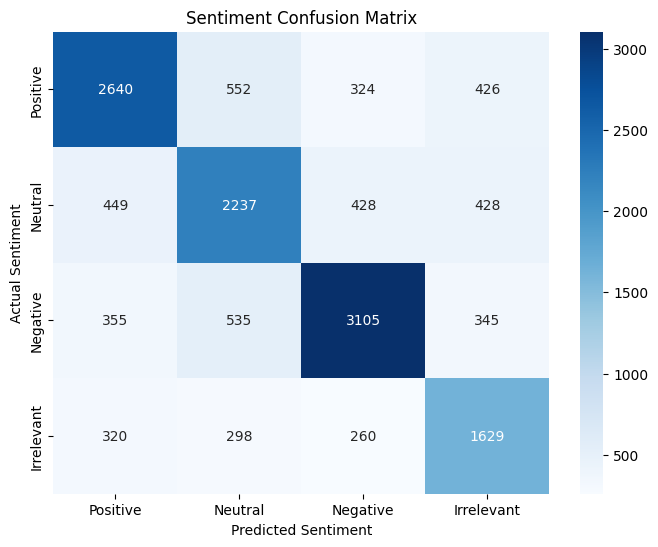

In [19]:
# Predict sentiments
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:",
      round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix with actual dataset labels (capitalized & including Irrelevant)
labels = ['Positive', 'Neutral', 'Negative', 'Irrelevant']
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.title('Sentiment Confusion Matrix')
plt.show()

In [20]:
# Enter a new tweet
new_tweet = [
    "The airline service is excellent and staff is very helpful"
]

# Clean the tweet
cleaned_tweet = [clean_text(new_tweet[0])]

# Convert into numerical format
tweet_vector = tfidf.transform(cleaned_tweet)

# Predict sentiment
prediction = model.predict(tweet_vector)

print("New Tweet:", new_tweet[0])

print("Predicted Sentiment:", prediction[0])

New Tweet: The airline service is excellent and staff is very helpful
Predicted Sentiment: Negative
